# Applied Machine Learning for Engineering

## Learning objectives

By the end of this lesson, you should be able to:

1. explain the idea of **modeling** in machine learning;
2. define **what machine learning is** in the context of Electrical Engineering;
3. distinguish **underfitting** and **overfitting**;
4. interpret the idea of **correction** in classification problems;
5. understand the **bias-variance dilemma**;
6. recognize the role of **feature extraction and selection**.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import mean_squared_error

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 320,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

COLORS = {
    "blue": "#2563eb",
    "cyan": "#0891b2",
    "orange": "#ea580c",
    "gold": "#f59e0b",
    "green": "#16a34a",
    "gray": "#64748b",
    "dark": "#0f172a",
}

rng = np.random.default_rng(42)


def save_figure(fig, filename, caption=None, bottom=0.14):
    if caption:
        fig.subplots_adjust(bottom=bottom)
        fig.text(0.5, 0.02, caption, ha="center", va="bottom", fontsize=9, color="#334155", wrap=True)
    path = FIG_DIR / filename
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    return path

## 1. Analyzed scenario

We wish to **detect faults in an induction motor** using **current**, **vibration**, and **temperature** signals.

The signals are noisy and change with load and environment. There is not always a complete physical model for the decision. In many cases, we need to turn data into **diagnosis**, **forecast**, or **alarm**.

**Central question:** how to learn useful patterns without just memorizing the training set?


## 2. Mathematical Modeling

Modeling is representing a real system through a mathematical abstraction.

In machine learning, we seek a function relating the input variables to the estimated output:

$$ \hat{y} = f_\theta(x) $$

where:

- $$ x = [x_1, x_2, \dots, x_n]^T $$

is the input vector, formed by one or more variables of the problem;
- each component $x_i$ may represent temperature, voltage, current, frequency, or another observed feature;
- $f_\theta$ is a parameterized mathematical model;
- $\theta$ is the set of parameters adjusted during training;
- $\hat{y}$ is the output estimated by the model;
- $y$ is the real output or reference value.

The evaluation criterion compares $\hat{y}$ with $y$ using metrics appropriate to the problem.


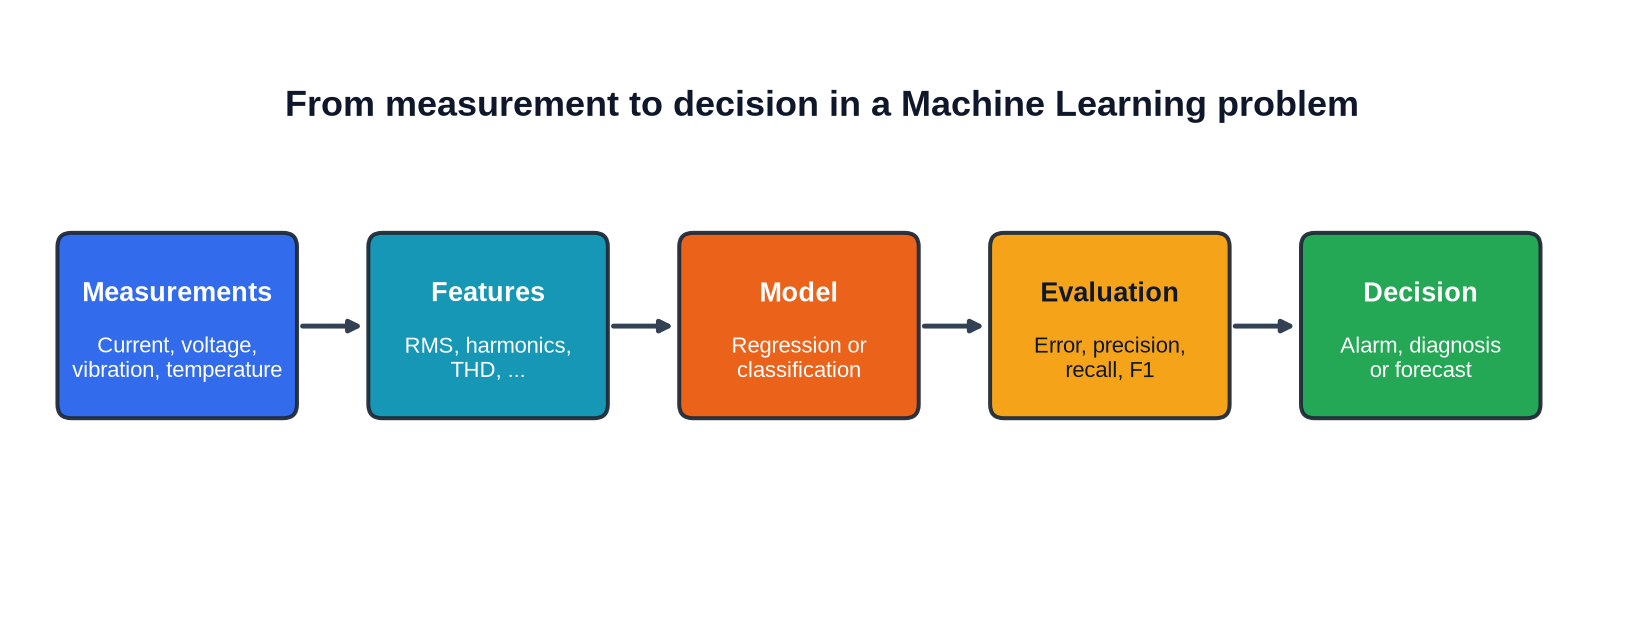

In [2]:
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.set_xlim(0, 14)
ax.set_ylim(0, 5.2)
ax.axis("off")

steps = [
    (0.4, COLORS["blue"], "Measurements", "Current, voltage,\nvibration, temperature"),
    (3.1, COLORS["cyan"], "Features", "RMS, harmonics,\nTHD, ..."),
    (5.8, COLORS["orange"], "Model", "Regression or\nclassification"),
    (8.5, COLORS["gold"], "Evaluation", "Error, precision,\nrecall, F1"),
    (11.2, COLORS["green"], "Decision", "Alarm, diagnosis\nor forecast"),
]

for x0, color, title, body in steps:
    box = patches.FancyBboxPatch(
        (x0, 1.7),
        2.0,
        1.55,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=color,
        edgecolor="#1f2937",
        linewidth=1.8,
        alpha=0.94,
    )
    ax.add_patch(box)
    text_color = COLORS["dark"] if color == COLORS["gold"] else "white"
    ax.text(x0 + 1.0, 2.75, title, ha="center", va="center", fontsize=12, fontweight="bold", color=text_color)
    ax.text(x0 + 1.0, 2.18, body, ha="center", va="center", fontsize=10, color=text_color)

for start, end in zip([2.45, 5.15, 7.85, 10.55], [3.05, 5.75, 8.45, 11.15]):
    ax.annotate("", xy=(end, 2.47), xytext=(start, 2.47), arrowprops=dict(arrowstyle="-|>", lw=2.2, color="#334155"))

ax.text(
    7.0,
    4.4,
    "From measurement to decision in a Machine Learning problem",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    color=COLORS["dark"],
)

path_fig1 = save_figure(fig, "01_modeling_pipeline.png", caption="", bottom=0.20)
plt.show()


## 3. What is Machine Learning?

Machine learning is the study of models that **learn patterns from data**.

Instead of explicitly programming all rules of the problem, we use data to adjust the model parameters. The goal is not only to reproduce well the data already observed, but to **generalize**, that is, to produce good answers for new data.

### When is this useful in Engineering?

- when the phenomenon is complex;
- when the physical model is incomplete;
- when we need an approximation for real-time decision.


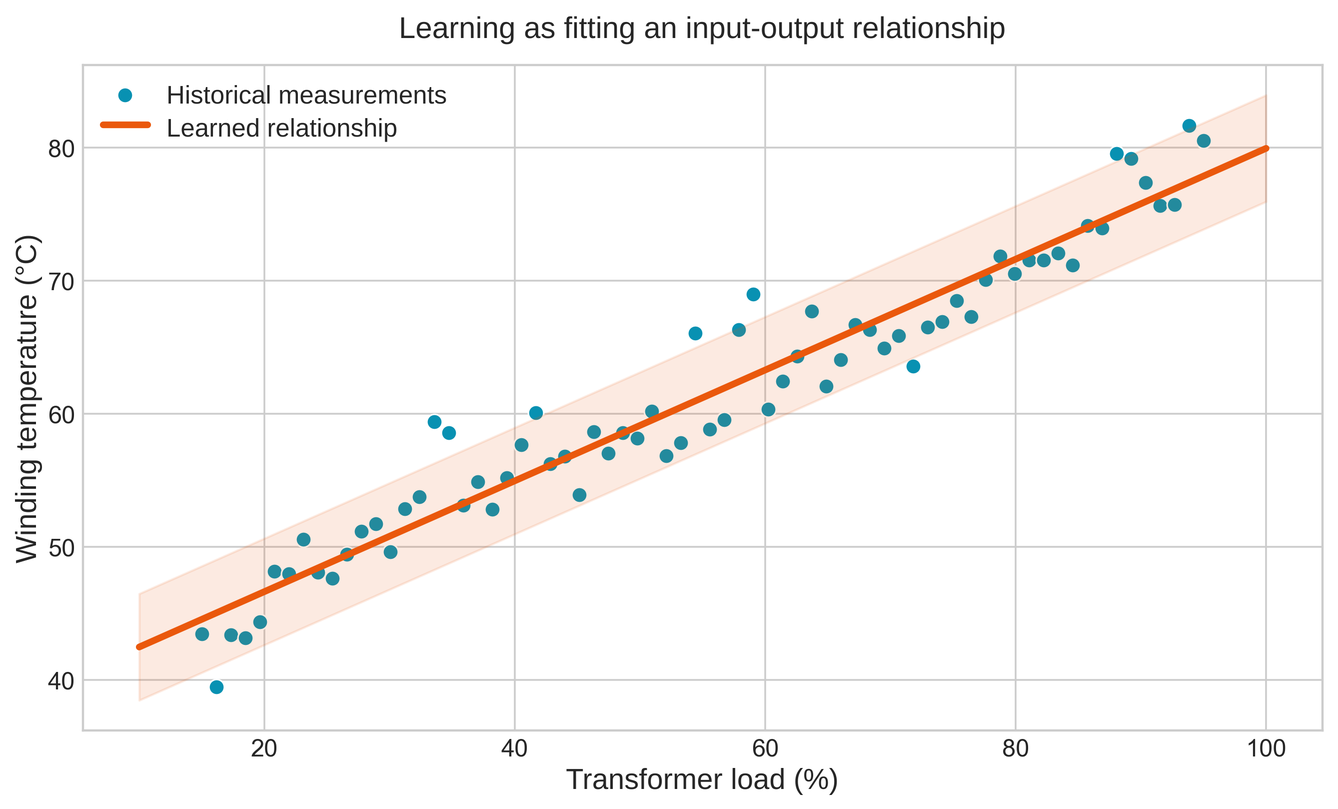

In [3]:

load = np.linspace(15, 95, 70)
temperature = 28 + 0.6 * load + 6 * np.sin(load / 18) + rng.normal(0, 2.2, size=load.size)

coef_linear = np.polyfit(load, temperature, 1)
x_grid = np.linspace(10, 100, 200)
y_grid = np.polyval(coef_linear, x_grid)

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.scatter(load, temperature, color=COLORS["cyan"], s=48, edgecolor="white", linewidth=0.7, label="Historical measurements")
ax.plot(x_grid, y_grid, color=COLORS["orange"], linewidth=3, label="Learned relationship")
ax.fill_between(x_grid, y_grid - 4, y_grid + 4, color=COLORS["orange"], alpha=0.12)
ax.set_xlabel("Transformer load (%)")
ax.set_ylabel("Winding temperature (°C)")
ax.set_title("Learning as fitting an input-output relationship", pad=12)
ax.legend(frameon=False, loc="upper left")

path_fig2 = save_figure(fig, "02_learning_examples.png", caption="", bottom=0.16)
plt.show()


## 4. Underfitting and overfitting

### Bias and variance

**Bias** is the error caused by overly simplifying hypotheses in the model. A high-bias model tends not to adequately capture the real behavior of the data.

**Variance** is the sensitivity of the model to small variations in the training set. A high-variance model overfits the seen data and loses generalization ability.


### Underfitting and overfitting

**Underfitting**

- model too simple;
- high bias;
- misses the structure of the problem;
- high error even in training.

**Overfitting**

- model too complex;
- high variance;
- fits training noise;
- fails to generalize.

**Key idea:** a good model learns the relevant pattern of the system, not the accidental fluctuations of a specific sample.


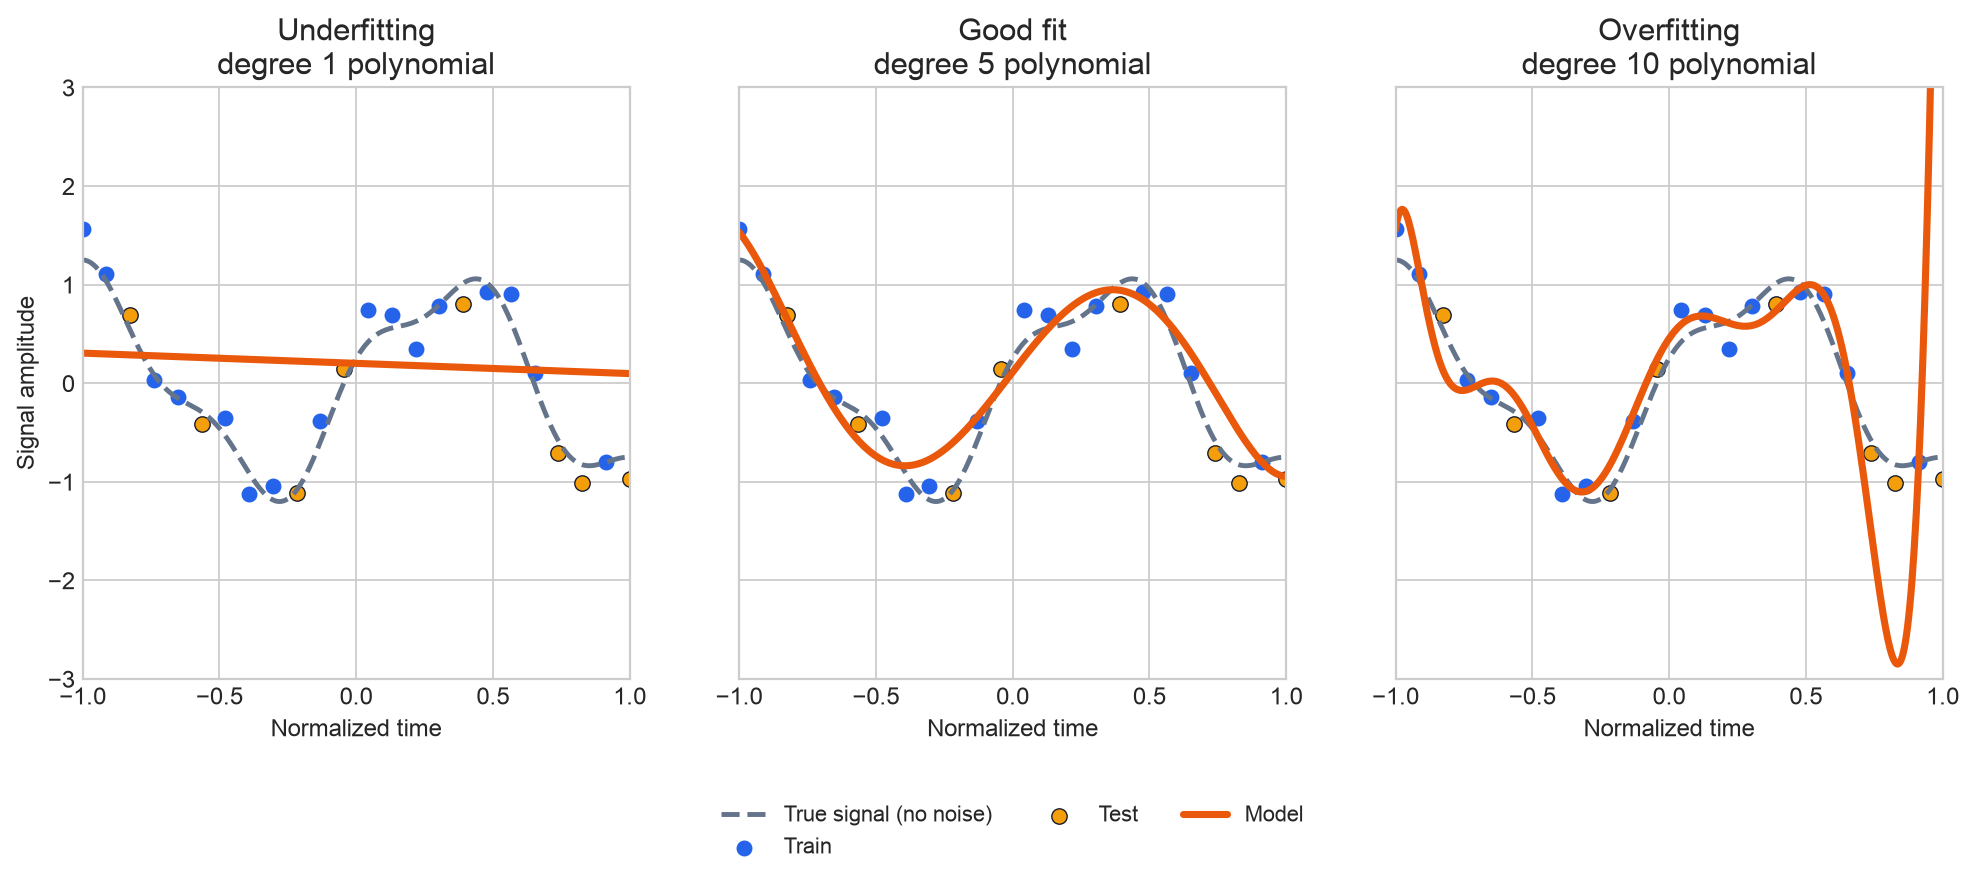

,Regime,Degree,Train MSE,Test MSE
0,Underfitting,1,0.602914,0.740853
1,Good fit,5,0.059245,0.126932
2,Overfitting,10,0.015131,15.999659


In [4]:

sine_wave = lambda x: np.sin(1.5 * np.pi * x) + 0.25 * np.cos(4 * np.pi * x)

x_poly = np.linspace(-1, 1, 24)
y_poly_true = sine_wave(x_poly)
y_poly_obs = y_poly_true + rng.normal(0, 0.18, size=x_poly.size)

idx = np.arange(x_poly.size)
rng_poly = np.random.default_rng(7)
rng_poly.shuffle(idx)
train_idx = np.sort(idx[:16])
test_idx = np.sort(idx[16:])

x_train_polyfit = x_poly[train_idx]
y_train_polyfit = y_poly_obs[train_idx]
x_test_polyfit = x_poly[test_idx]
y_test_polyfit = y_poly_obs[test_idx]

x_dense_polyfit = np.linspace(-1, 1, 500)
y_dense_polyfit = sine_wave(x_dense_polyfit)

degrees = [1, 5, 10]
names = ["Underfitting", "Good fit", "Overfitting"]
poly_fits = []

for degree, name in zip(degrees, names):
    coef = np.polyfit(x_train_polyfit, y_train_polyfit, degree)
    poly_fits.append(
        {
            "name": name,
            "degree": degree,
            "coef": coef,
            "pred_dense": np.polyval(coef, x_dense_polyfit),
            "mse_train": mean_squared_error(y_train_polyfit, np.polyval(coef, x_train_polyfit)),
            "mse_test": mean_squared_error(y_test_polyfit, np.polyval(coef, x_test_polyfit)),
        }
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, fit in zip(axes, poly_fits):
    ax.plot(x_dense_polyfit, y_dense_polyfit, "--", color=COLORS["gray"], linewidth=2.2, label="True signal (no noise)")
    ax.scatter(x_train_polyfit, y_train_polyfit, color=COLORS["blue"], s=38, label="Train")
    ax.scatter(x_test_polyfit, y_test_polyfit, color=COLORS["gold"], s=48, edgecolor=COLORS["dark"], linewidth=0.6, label="Test")
    ax.plot(x_dense_polyfit, fit["pred_dense"], color=COLORS["orange"], linewidth=3.2, label="Model")
    ax.set_title(f"{fit['name']}\ndegree {fit['degree']} polynomial")
    ax.set_xlabel("Normalized time")
    ax.set_xlim(-1, 1)
    ax.set_ylim(-3, 3)

axes[0].set_ylabel("Signal amplitude")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
caption = "Figure 3. Three model complexity regimes: underfitting, good fit, and overfitting when trying to represent a noisy signal."
path_fig3 = save_figure(fig, "03_underfitting_overfitting.png", caption="", bottom=0.22)
plt.show()

pd.DataFrame(
    [{"Regime": a["name"], "Degree": a["degree"], "Train MSE": a["mse_train"], "Test MSE": a["mse_test"]} for a in poly_fits]
)


### Reading the figure

- **Underfitting:** the hypothesis is too poor to capture the curvature of the phenomenon.
- **Good fit:** the model follows the dominant trend without oscillating too much.
- **Overfitting:** the curve follows spurious details that belong to the training set noise.

In current or vibration signals, an overfitted model may look excellent on the bench and fail when the equipment changes load, environment, or regime.


## 5. Bias-variance

The bias-variance dilemma summarizes an important trade-off:

- increasing complexity usually **reduces bias**;
- increasing complexity usually **increases variance**;
- good generalization normally appears in an **intermediate** complexity range.


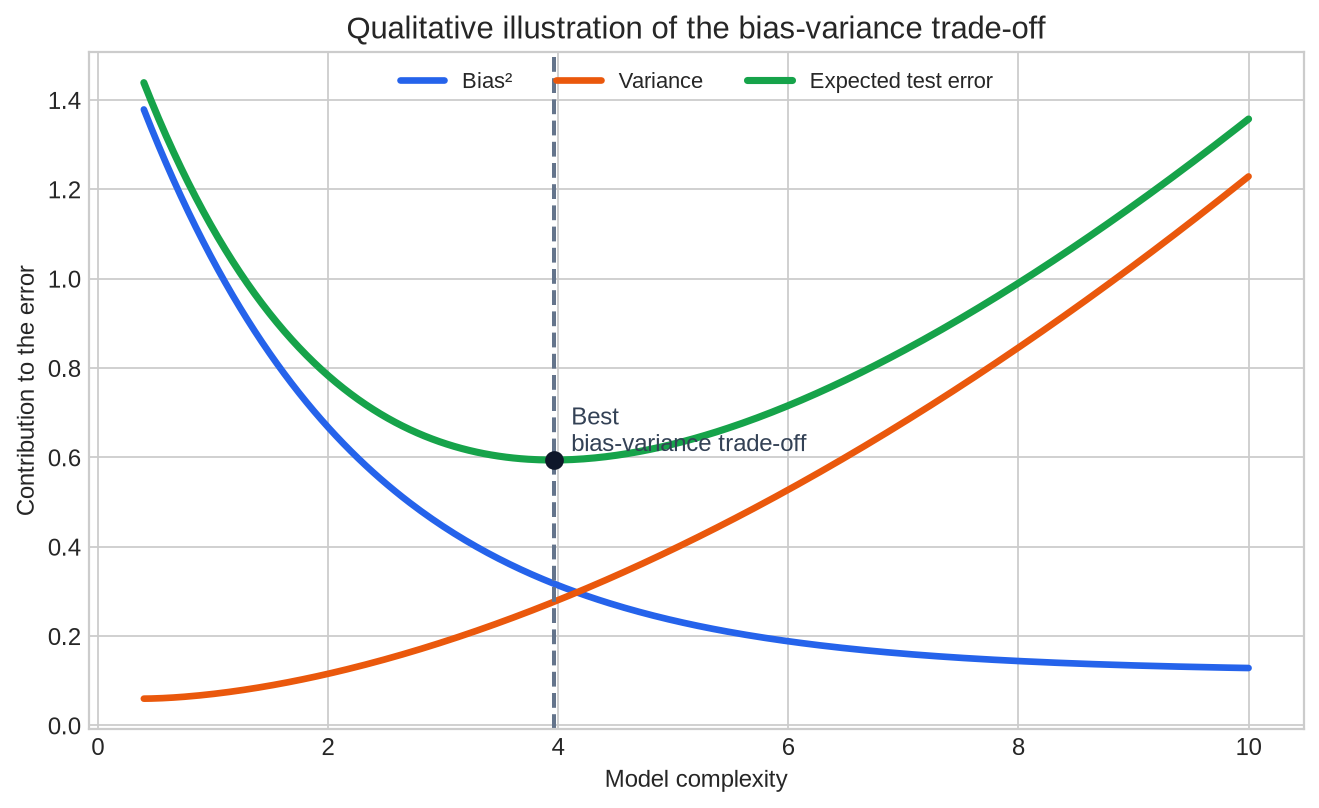

In [5]:

complexity = np.linspace(0.4, 10, 300)
bias_sq = 1.55 * np.exp(-0.52 * complexity) + 0.12
variance = 0.06 + 0.025 * (complexity - 0.4) ** 1.7
test_error = bias_sq + variance
best_idx = np.argmin(test_error)

fig, ax = plt.subplots(figsize=(9.8, 5.5))
ax.plot(complexity, bias_sq, color=COLORS["blue"], linewidth=3, label="Bias²")
ax.plot(complexity, variance, color=COLORS["orange"], linewidth=3, label="Variance")
ax.plot(complexity, test_error, color=COLORS["green"], linewidth=3.2, label="Expected test error")
ax.axvline(complexity[best_idx], color=COLORS["gray"], linestyle="--", linewidth=1.8)
ax.scatter([complexity[best_idx]], [test_error[best_idx]], color=COLORS["dark"], s=55, zorder=5)
ax.text(
    complexity[best_idx] + 0.15,
    test_error[best_idx] + 0.02,
    "Best\nbias-variance trade-off",
    color="#334155",
)
ax.set_xlabel("Model complexity")
ax.set_ylabel("Contribution to the error")
ax.set_title("Qualitative illustration of the bias-variance trade-off")
ax.legend(frameon=False, loc="upper center", ncol=3)

path_fig5 = save_figure(fig, "05_bias_variance.png", caption="", bottom=0.16)
plt.show()


### How to reduce bias or variance?

**To reduce bias**

- use a more expressive model;
- build more informative features;
- improve the representation of the phenomenon.

**To reduce variance**

- obtain more data;
- reduce complexity;
- apply regularization;
- validate the model on unseen data.


## 6. Correction

In classification problems, knowing only how many hits the model had is not enough. We also need to understand **which types of error** it makes.

In predictive maintenance, failing to detect a real fault is usually more serious than issuing a false alarm. Therefore, the notion of correction needs to be analyzed more carefully.


### Possible outcomes in binary classification

Considering the positive class as **fault**, we have four possible outcomes:

- **TP** (true positive): the model predicted fault and the real condition was also fault;
- **FP** (false positive): the model predicted fault, but the real condition was normal;
- **FN** (false negative): the model predicted normal, but the real condition was fault;
- **TN** (true negative): the model predicted normal and the real condition was also normal.


### Metrics for classification evaluation

The most common metrics are:

$ \text{Precision} = \frac{TP}{TP + FP}$

Among all cases classified as fault, how many were really faults.

$ \text{Recall} = \frac{TP}{TP + FN}$

Among all real faults, how many were correctly detected.

$ F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$

The **$F_1$** seeks to balance precision and recall.


### Accuracy alone can mislead

When faults are rare, always predicting **normal** can yield apparently high accuracy. This does not mean the classifier is useful.

In Engineering, the metric must reflect the **operational cost of the error**.


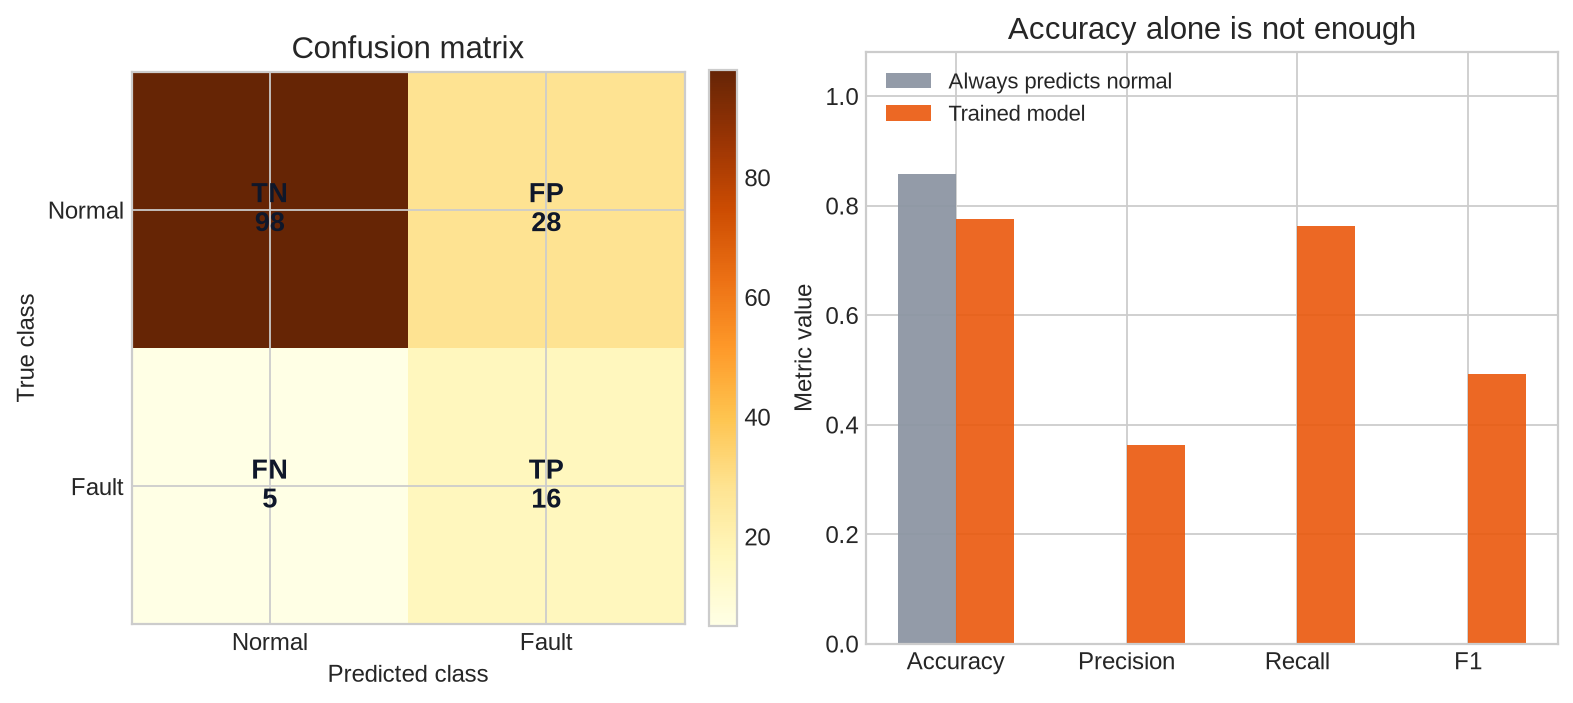

,Strategy,Accuracy,Precision,Recall,F1
0,Always predicts normal,0.857143,0.000000,0.000000,0.000000
1,Trained model,0.775510,0.363636,0.761905,0.492308


In [6]:
cm = np.array([[98, 28], [5, 16]])
classes = ["Normal", "Fault"]

tp = cm[1, 1]
fp = cm[0, 1]
fn = cm[1, 0]
tn = cm[0, 0]

acc_baseline = (tn + fp) / cm.sum()
prec_baseline = 0.0
rec_baseline = 0.0
f1_baseline = 0.0

acc_model = (tp + tn) / cm.sum()
prec_model = tp / (tp + fp)
rec_model = tp / (tp + fn)
model_f1 = 2 * prec_model * rec_model / (prec_model + rec_model)

metric_cols = ["Accuracy", "Precision", "Recall", "F1"]
baseline_vals = [acc_baseline, prec_baseline, rec_baseline, f1_baseline]
trained_vals = [acc_model, prec_model, rec_model, model_f1]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.05, 1.2]})

im = axes[0].imshow(cm, cmap="YlOrBr")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        label = [["TN", "FP"], ["FN", "TP"]][i][j]
        axes[0].text(j, i, f"{label}\n{cm[i, j]}", ha="center", va="center", fontsize=12, fontweight="bold", color=COLORS["dark"])
axes[0].set_xticks([0, 1], classes)
axes[0].set_yticks([0, 1], classes)
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("True class")
axes[0].set_title("Confusion matrix")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

x = np.arange(len(metric_cols))
width = 0.34
axes[1].bar(x - width / 2, baseline_vals, width=width, color="#8d96a3", alpha=0.95, label="Always predicts normal")
axes[1].bar(x + width / 2, trained_vals, width=width, color=COLORS["orange"], alpha=0.9, label="Trained model")
axes[1].set_xticks(x, metric_cols)
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("Metric value")
axes[1].set_title("Accuracy alone is not enough")
axes[1].legend(frameon=False, loc="upper left")

path_fig4 = save_figure(fig, "04_classification_metrics_v2.png", caption="", bottom=0.16)
plt.show()
pd.DataFrame(
    {
        "Strategy": ["Always predicts normal", "Trained model"],
        "Accuracy": [acc_baseline, acc_model],
        "Precision": [prec_baseline, prec_model],
        "Recall": [rec_baseline, rec_model],
        "F1": [f1_baseline, model_f1],
    }
)


## 7. Feature extraction and selection

In many Electrical Engineering problems, we do not feed the raw signal directly to the model. First we extract **resources** or **features** that summarize important information.

Examples of features extracted from signals:

- RMS;
- kurtosis;
- crest factor;
- energy in frequency bands;
- zero-crossing rate;
- harmonics and total distortion.

After that, we can perform **feature selection**, keeping only the most informative attributes for the task.


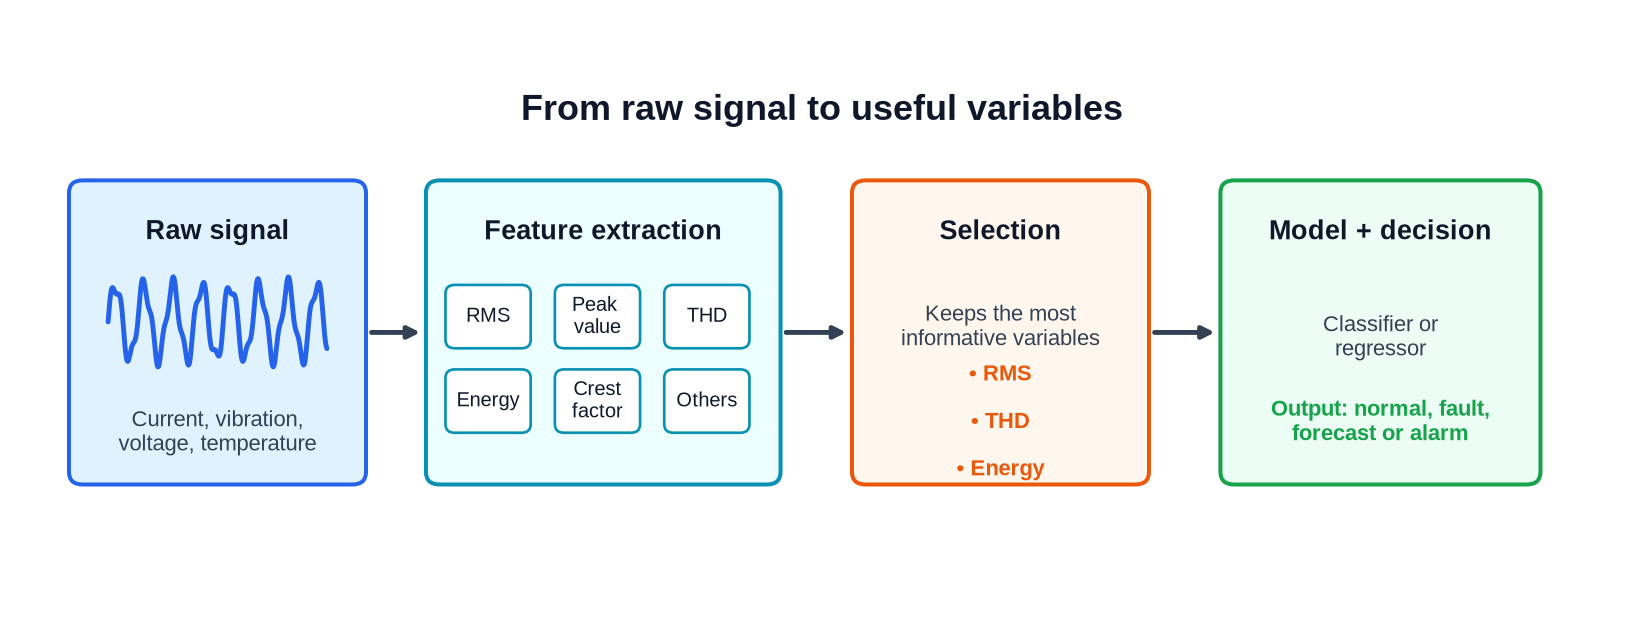

In [7]:

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.set_xlim(0, 14)
ax.set_ylim(0, 5.6)
ax.axis("off")

raw_box = patches.FancyBboxPatch((0.5, 1.2), 2.5, 2.8, boxstyle="round,pad=0.04,rounding_size=0.12", facecolor="#e0f2fe", edgecolor=COLORS["blue"], linewidth=1.8)
feat_box = patches.FancyBboxPatch((3.6, 1.2), 3.0, 2.8, boxstyle="round,pad=0.04,rounding_size=0.12", facecolor="#ecfeff", edgecolor=COLORS["cyan"], linewidth=1.8)
select_box = patches.FancyBboxPatch((7.3, 1.2), 2.5, 2.8, boxstyle="round,pad=0.04,rounding_size=0.12", facecolor="#fff7ed", edgecolor=COLORS["orange"], linewidth=1.8)
model_box = patches.FancyBboxPatch((10.5, 1.2), 2.7, 2.8, boxstyle="round,pad=0.04,rounding_size=0.12", facecolor="#ecfdf5", edgecolor=COLORS["green"], linewidth=1.8)
for box in [raw_box, feat_box, select_box, model_box]:
    ax.add_patch(box)

xs = np.linspace(0.8, 2.7, 300)
ys = 2.7 + 0.35 * np.sin(8 * np.pi * (xs - 0.8)) + 0.08 * np.sin(22 * np.pi * (xs - 0.8))
ax.plot(xs, ys, color=COLORS["blue"], linewidth=2.2)
ax.text(1.75, 3.55, "Raw signal", ha="center", va="center", fontsize=12, fontweight="bold", color=COLORS["dark"])
ax.text(1.75, 1.65, "Current, vibration,\nvoltage, temperature", ha="center", va="center", fontsize=10, color="#334155")

ax.text(5.1, 3.55, "Feature extraction", ha="center", va="center", fontsize=12, fontweight="bold", color=COLORS["dark"])
feature_labels = ["RMS", "Peak \nvalue", "THD", "Energy", "Crest\nfactor", "Others"]
feature_positions = [(4.1, 2.75), (5.05, 2.75), (6.0, 2.75), (4.1, 1.95), (5.05, 1.95), (6.0, 1.95)]
for (xp, yp), label in zip(feature_positions, feature_labels):
    chip = patches.FancyBboxPatch((xp - 0.35, yp - 0.28), 0.7, 0.56, boxstyle="round,pad=0.02,rounding_size=0.08", facecolor="white", edgecolor=COLORS["cyan"], linewidth=1.2)
    ax.add_patch(chip)
    ax.text(xp, yp, label, ha="center", va="center", fontsize=9, color=COLORS["dark"])

ax.text(8.55, 3.55, "Selection", ha="center", va="center", fontsize=12, fontweight="bold", color=COLORS["dark"])
ax.text(8.55, 2.65, "Keeps the most\ninformative variables", ha="center", va="center", fontsize=10, color="#334155")
for yp, label in zip([2.2, 1.75, 1.3], ["RMS", "THD", "Energy"]):
    ax.text(8.55, yp, f"• {label}", ha="center", va="center", fontsize=10, color=COLORS["orange"], fontweight="bold")

ax.text(11.85, 3.55, "Model + decision", ha="center", va="center", fontsize=12, fontweight="bold", color=COLORS["dark"])
ax.text(11.85, 2.55, "Classifier or\nregressor", ha="center", va="center", fontsize=10, color="#334155")
ax.text(11.85, 1.75, "Output: normal, fault,\nforecast or alarm", ha="center", va="center", fontsize=10, color=COLORS["green"], fontweight="bold")

for start, end in [((3.05, 2.6), (3.55, 2.6)), ((6.65, 2.6), (7.25, 2.6)), ((9.85, 2.6), (10.45, 2.6))]:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", lw=2.2, color="#334155"))

ax.text(7.0, 4.7, "From raw signal to useful variables", ha="center", va="center", fontsize=16, fontweight="bold", color=COLORS["dark"])
caption = "Figure 6. Feature extraction and selection flow: time- and frequency-domain attributes are derived from the raw signal, of which the most informative for classification remain."
path_fig6 = save_figure(fig, "06_feature_extraction_selection.png", caption="", bottom=0.20)
plt.show()


### Why does feature extraction help?

One way to see this is to compare two signals in the time domain and then observe how **summarized features** make separation clearer.

In the graph below, the **normal** signal is approximately sinusoidal, while the **faulty/noisy** signal presents distortion, noise, and additional harmonic content. On the right, we extract few features and show how they help distinguish the operating regimes.


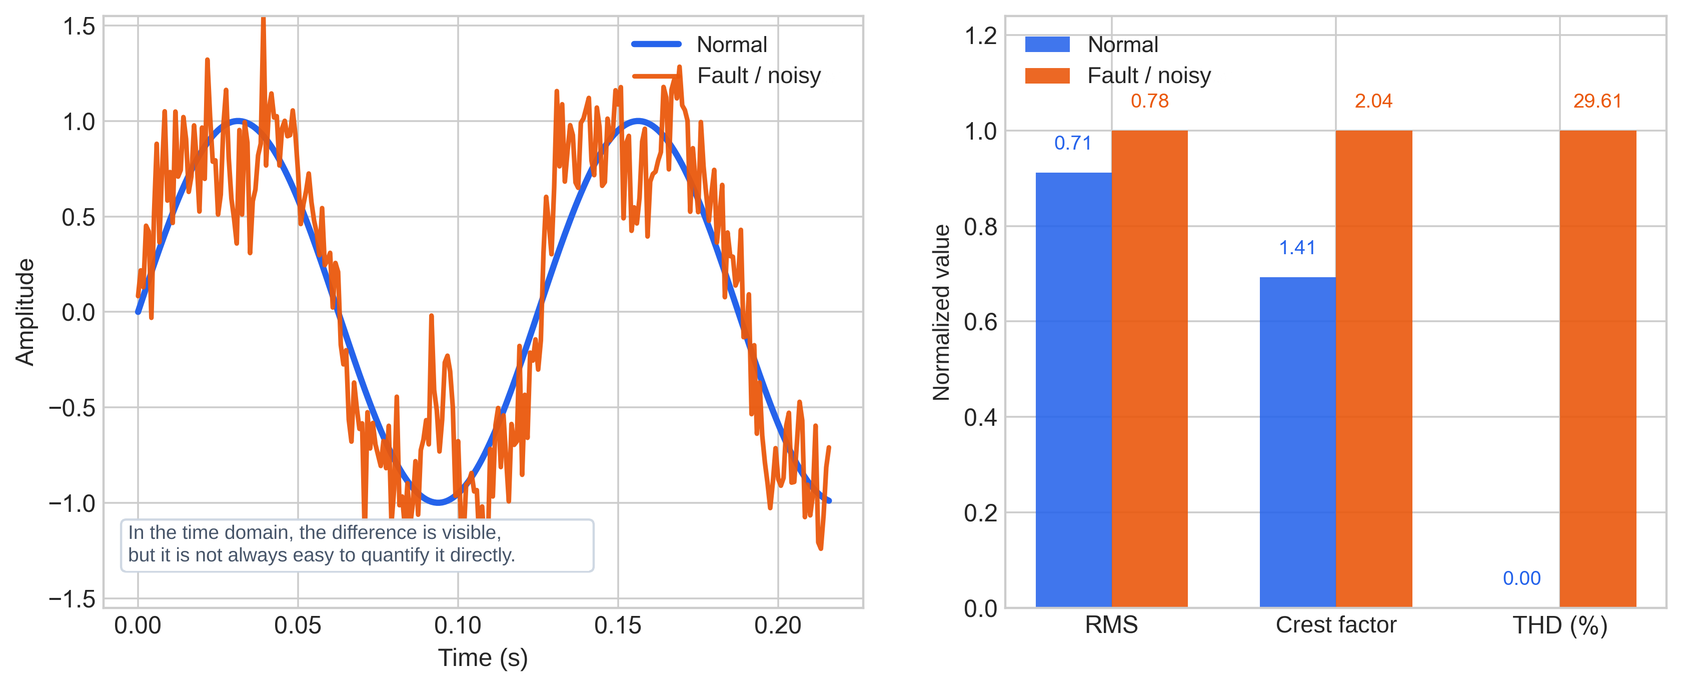

In [8]:
fs = 1200
T = 1.0
n = int(fs * T)
t = np.linspace(0, T, n, endpoint=False)

signal_normal = 1.0 * np.sin(2 * np.pi * 8 * t)
signal_fault = (
    1.0 * np.sin(2 * np.pi * 8 * t)
    + 0.30 * np.sin(2 * np.pi * 24 * t)
    + 0.16 * np.sin(2 * np.pi * 55 * t)
    + 0.20 * rng.normal(size=t.size)
)


def rms(x):
    return np.sqrt(np.mean(x**2))


def crest_factor(x):
    return np.max(np.abs(x)) / rms(x)


def thd_percent(x, fs, f0):
    freqs = np.fft.rfftfreq(x.size, d=1 / fs)
    amp = np.abs(np.fft.rfft(x))
    k0 = np.argmin(np.abs(freqs - f0))
    fund = amp[k0]
    harmonic_powers = []
    for k in range(2, 8):
        kk = np.argmin(np.abs(freqs - k * f0))
        harmonic_powers.append(amp[kk] ** 2)
    return 100 * np.sqrt(np.sum(harmonic_powers)) / fund


features_normal = {
    "RMS": rms(signal_normal),
    "Crest factor": crest_factor(signal_normal),
    "THD (%)": thd_percent(signal_normal, fs, 8),
}
features_fault = {
    "RMS": rms(signal_fault),
    "Crest factor": crest_factor(signal_fault),
    "THD (%)": thd_percent(signal_fault, fs, 8),
}

labels = list(features_normal.keys())
vals_normal = np.array([features_normal[k] for k in labels], dtype=float)
vals_fault = np.array([features_fault[k] for k in labels], dtype=float)
vals_ref = np.maximum(vals_normal, vals_fault)
vals_normal_scaled = vals_normal / vals_ref
vals_fault_scaled = vals_fault / vals_ref

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.8), gridspec_kw={"width_ratios": [1.15, 1.0]})

# Left: time-domain signals
ax = axes[0]
window = slice(0, 260)
ax.plot(t[window], signal_normal[window], color=COLORS["blue"], linewidth=2.8, label="Normal")
ax.plot(t[window], signal_fault[window], color=COLORS["orange"], linewidth=2.1, alpha=0.95, label="Fault / noisy")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_ylim(-1.55, 1.55)
ax.legend(frameon=False, loc="upper right")
ax.text(
    0.03,
    0.07,
    "In the time domain, the difference is visible,\nbut it is not always easy to quantify it directly.",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=9.4,
    color="#475569",
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#cbd5e1", alpha=0.92),
)

# Right: summarized features
ax = axes[1]
x = np.arange(len(labels))
width = 0.34
ax.bar(x - width / 2, vals_normal_scaled, width=width, color=COLORS["blue"], alpha=0.88, label="Normal")
ax.bar(x + width / 2, vals_fault_scaled, width=width, color=COLORS["orange"], alpha=0.90, label="Fault / noisy")
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.24)
ax.set_ylabel("Normalized value")
ax.legend(frameon=False, loc="upper left")

for i, (v_normal, v_fault) in enumerate(zip(vals_normal, vals_fault)):
    ax.text(i - width / 2, vals_normal_scaled[i] + 0.04, f"{v_normal:.2f}", ha="center", va="bottom", fontsize=9, color=COLORS["blue"])
    ax.text(i + width / 2, vals_fault_scaled[i] + 0.04, f"{v_fault:.2f}", ha="center", va="bottom", fontsize=9, color=COLORS["orange"])

path_fig7 = save_figure(fig, "07_feature_extraction_insight.png", caption="", bottom=0.18)
plt.show()


### Practical impact

The quality of the features directly influences the separation ability between classes or the quality of a regression.

In the context of Electrical Engineering:

- good features can facilitate identifying bearing faults, inter-turn shorts, or misalignments;
- poorly chosen features may hide the relevant pattern;
- feature selection helps reduce noise, computational cost, and overfitting risk.


## 8. Suggested exercises

1. **Underfitting and overfitting study**: change the polynomial degree in the example with `np.polyfit` and describe in which range the test error is smaller.
2. **Cost of error**: explain why, in predictive maintenance, a false negative can be more serious than a false positive.
3. **Feature selection**: suppose ten attributes extracted from current signals. Propose a criterion to choose only three for an embedded system with memory limitation.
4. **Demand forecast**: build a small synthetic set with ambient temperature, time of day, and historical load to estimate electrical demand. Discuss how to identify bias and variance in the model.
5. **Diagnosis with signals**: describe which time- and frequency-domain attributes could help differentiate normal and fault operation in an inverter.


## 9. Base reference

The conceptual organization of this lesson follows the content of the expository material and the bibliographic basis indicated for the topic.

- Joel Grus, *Data Science do Zero*.
- Chapter 11: **Machine Learning**.
